# yada MCP

Exercises yada's MCP server — the interface a client (Goose) sees.

**Start the server first.** In VSCode run the **yada MCP server (http)**
configuration, or from the repo root:

```
YADA_MCP_TRANSPORT=streamable-http python -m mcp_server.server
```


In [33]:
%reload_ext autoreload
%autoreload 2

from utils import (call_tool, first_text, list_mcp_tools, show_result,
                   show_tool_schema)

## Tools

What the server advertises. This is the whole surface a client routes over,
so it is also the tool-count budget.


In [34]:
await list_mcp_tools()


plot: Chart data that YOU ALREADY HAVE, from the request, and return an image.
plot_report: Render a stored time series report as a chart and return it as an image.
search_code: Search Troy Stribling's indexed code repositories by meaning and return ranked excerpts with their file paths (10,763 files, 415,006 indexed chunks).
- query: what to look for, in natural language.
- repo: a repository, written 'account/name' as describe_code reports it, or just the name when it is unambiguous.
describe_code: What the code repositories contain: accounts, repositories, file types and counts, under any filters given.
search_research_library: Search Troy Stribling's research library -- papers, research notes and blog posts -- by meaning, returning ranked excerpts (64 files, 4,875 indexed chunks).
- query: what to look for, in natural language.
- authors: who wrote it.
describe_research_library: What the research library contains: authors, titles, shelves and counts, under any filters given.
search

## MCP Method

MCP schema definition for specied tool.

In [31]:
tool_name = "open_plot_report_view"
await show_tool_schema(tool_name, raw=True)

{
  "_meta": {
    "io.modelcontextprotocol/ui": {
      "resourceUri": "ui://yada/report-picker",
      "visibility": [
        "model",
        "app"
      ]
    },
    "ui": {
      "resourceUri": "ui://yada/report-picker",
      "visibility": [
        "model",
        "app"
      ]
    },
    "ui/resourceUri": "ui://yada/report-picker",
    "ui/visibility": [
      "model",
      "app"
    ]
  },
  "description": "Open the plot-report view: the caller's saved reports as a table they pick from, which then plots the one they chose.\nTakes no arguments \u2014 it returns every report the caller has, and the view filters them in the browser by title, description or series id.\nUse this when the user wants to CHOOSE which report to plot \u2014 'in a plot time series report view show me my reports', 'let me pick a report to chart', or any request naming a report view. When the user has already named one report, call plot_report directly instead; this view is for choosing among several.\n

In [32]:
await show_tool_schema(tool_name)

open_plot_report_view
  Open the plot-report view: the caller's saved reports as a table they pick from, which then plots the one they chose.
Takes no arguments — it returns every report the caller has, and the view filters them in the browser by title, description or series id.
Use this when the user wants to CHOOSE which report to plot — 'in a plot time series report view show me my reports', 'let me pick a report to chart', or any request naming a report view. When the user has already named one report, call plot_report directly instead; this view is for choosing among several.
STOP after calling this. Do NOT call plot_report yourself: the view asks for the plot itself once the user picks, and calling it here would chart a report nobody chose. The user's pick arrives as a new request naming its report_id.



{'properties': {}, 'type': 'object', 'title': 'open_plot_report_viewArguments'}

### A time series from data in the request


## Tennessee Population

Tennessee's population grew steadily from 6.91 million in 2020 to 7.05 million in 2023, an increase of about 140,000 residents over three years (roughly 2.0% total growth).

- **Consistent upward trend:** Every year saw positive growth, reflecting sustained in-migration and natural increase.
- **Front-loaded gains:** The largest single-year jump occurred from 2020 to 2021 (+0.07 million), after which annual increases tapered slightly to +0.04 million (2021 to 2022) and +0.03 million (2022 to 2023).
- **Decelerating pace:** While population continues to rise, the slowing year-over-year increments suggest growth may be moderating.

[image/png] 39,017 bytes (52,024 base64 chars)


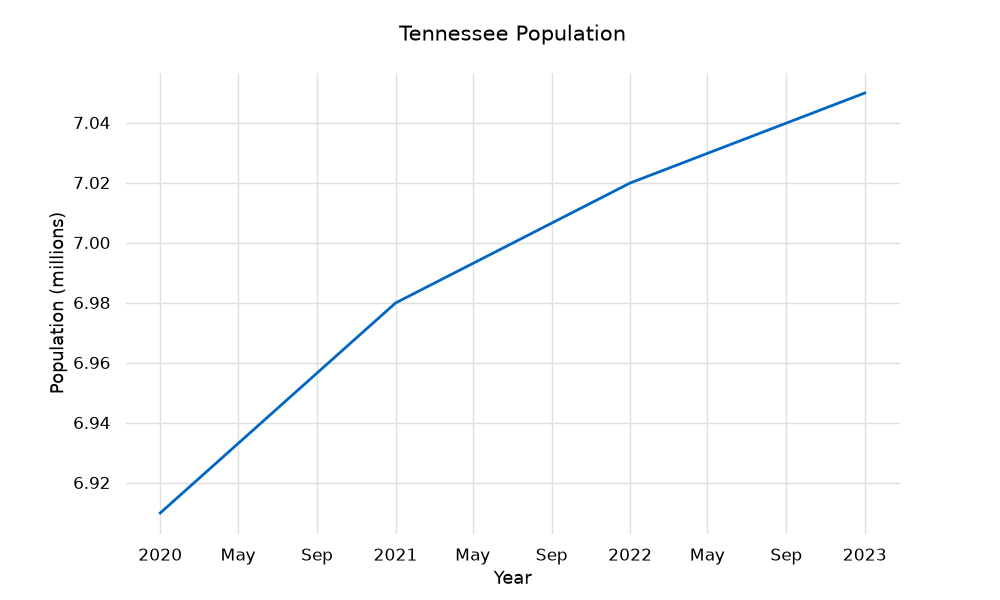

In [5]:
result = await call_tool("plot", {
    "request": "Plot a time series titled 'Tennessee population' with times "
               "2020, 2021, 2022, 2023 and values 6.91, 6.98, 7.02, 7.05.",
})
show_result(result)


### A comparison — two series on one chart


## Tennessee vs. Alabama, 2020-2023

- **Levels:** Tennessee sits consistently higher than Alabama across all four years, with a gap of roughly 1.9 points that stays nearly constant.
- **Growth:** Tennessee rose from 6.91 to 7.05, a gain of 0.14 (about 2.0%). Alabama rose from 5.03 to 5.11, a gain of 0.08 (about 1.6%).
- **Trend:** Both series climbed steadily each year with no reversals. Tennessee's largest year-over-year jump came in 2020-2021 (+0.07), while Alabama's largest came in 2022-2023 (+0.04).
- **Takeaway:** Tennessee is both higher and growing slightly faster, so the gap between the two is widening marginally over the period.

[image/png] 31,868 bytes (42,492 base64 chars)


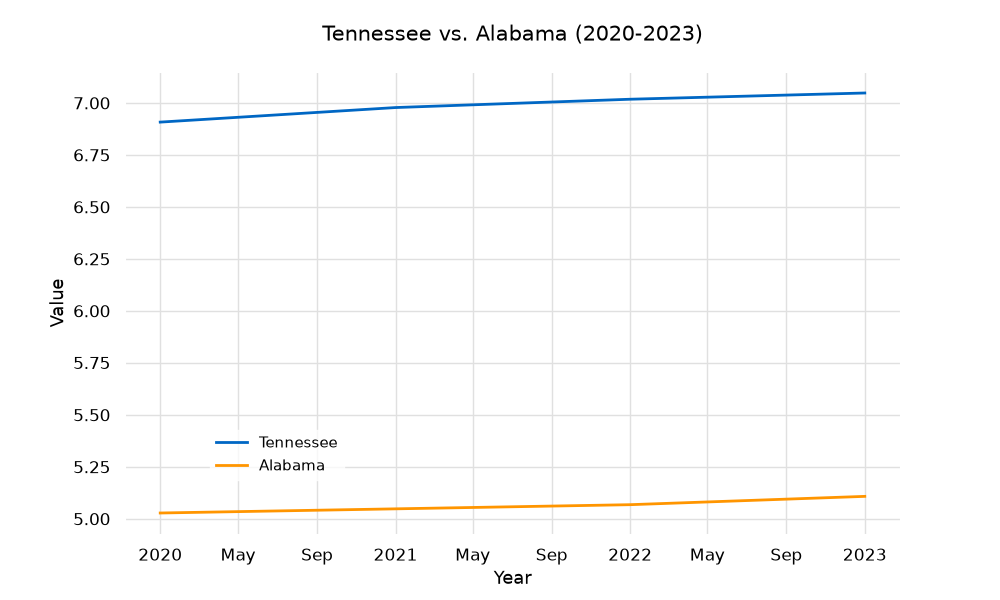

In [6]:
result = await call_tool("plot", {
    "request": "Compare two series over 2020-2023. Tennessee: 6.91, 6.98, "
               "7.02, 7.05. Alabama: 5.03, 5.05, 5.07, 5.11.",
})
show_result(result)


### A bar chart — the other branch of the router

Same tool, different sub-agent. Note the size: navi renders bars at
`dpi=300` against matplotlib's default 100 for curves, so these come back
roughly four times larger.


**Key observations:**
- **Tennessee** leads with 7.05 million residents, the most populous of the group.
- **Alabama** follows at 5.11 million, roughly 1.9 million fewer than Tennessee.
- **Kentucky** sits in the middle at 4.53 million.
- **Mississippi** is the smallest at 2.94 million, less than half of Tennessee's population.
- The spread between the largest and smallest state is 4.11 million, showing substantial variation across the group.

[image/png] 23,423 bytes (31,232 base64 chars)


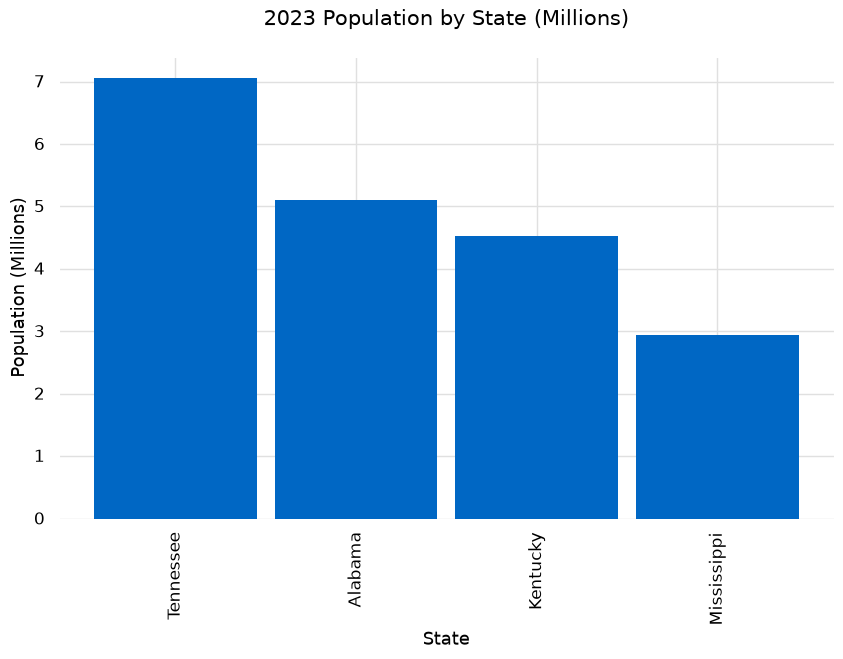

In [7]:
result = await call_tool("plot", {
    "request": "Bar chart of 2023 population in millions: Tennessee 7.05, "
               "Alabama 5.11, Kentucky 4.53, Mississippi 2.94.",
})
show_result(result)


### What a failure looks like

Worth knowing: the tool returns a text block rather than raising, so
`isError` stays `False`. A client sees a readable message, not an exception.


In [8]:
result = await call_tool("plot", {"request": "Plot nothing at all."})
show_result(result)


I can't create a plot with no data or specifications. To generate a chart, please provide:

- **What data** you want to visualize
- **What type of chart** you'd like (bar chart, time series, etc.)
- **Any relevant details** (time period, categories, values, etc.)

Feel free to describe what you'd like to see, and I'll create it for you.

## fetch_fred_series and plot_series

The honest path for anything in FRED, and the reason `plot` above now warns
against economic data. Asked to plot US GDP, `plot` could look nothing up, so the
values came from the model's memory: 22 of them, **2.4% out on average and 6.8%
at worst**, on a chart indistinguishable from a right one. The leaf agent even
said so — *"I don't have a live data connection"* — in a message the plumbing
then discarded.

These two obey `server.py`'s rule instead: *tools take ids and return rendered
artifacts; the model never holds series values*. `fetch_fred_series` returns a
`cache_id` and no observations; `plot_series` renders from the cache and never
from the request. Between them the model holds ids and pictures, never numbers.

They ship together on purpose — no other tool on this server mints a `cache_id`,
so a `plot_series` without a fetch would be unreachable.

Note the `_meta` block in the raw dump below: `plot_series` is bound to the same
chart App as `plot` and `plot_report`. The nested `ui` key is the one Goose
reads, and `fetch_fred_series` deliberately carries no binding at all.

In [9]:
tool_name = "plot_series"
await show_tool_schema(tool_name, raw=True)

{
  "_meta": {
    "io.modelcontextprotocol/ui": {
      "resourceUri": "ui://yada/plot",
      "visibility": [
        "model",
        "app"
      ]
    },
    "ui": {
      "resourceUri": "ui://yada/plot",
      "visibility": [
        "model",
        "app"
      ]
    },
    "ui/resourceUri": "ui://yada/plot",
    "ui/visibility": [
      "model",
      "app"
    ]
  },
  "description": "Chart one or more FRED series and return the image. **This is the tool for charting economic data** \u2014 it fetches what it needs and draws only from stored values, so the numbers are never ones the model supplied.\n- series_ids: FRED ids, e.g. ['GDP'] or ['GDP','GDPC1']. Fetched automatically if not already cached. This is the usual way to call it: 'plot US GDP' is one call.\n- cache_ids: ids already returned by fetch_fred_series. Mixes freely with series_ids.\n- title: chart title.\n- date_from / date_to: optional ISO dates to restrict the window.\nSeveral series are plotted together, with the

In [10]:
await show_tool_schema(tool_name)

plot_series
  Chart one or more FRED series and return the image. **This is the tool for charting economic data** — it fetches what it needs and draws only from stored values, so the numbers are never ones the model supplied.
- series_ids: FRED ids, e.g. ['GDP'] or ['GDP','GDPC1']. Fetched automatically if not already cached. This is the usual way to call it: 'plot US GDP' is one call.
- cache_ids: ids already returned by fetch_fred_series. Mixes freely with series_ids.
- title: chart title.
- date_from / date_to: optional ISO dates to restrict the window.
Several series are plotted together, with the plot type and axes chosen from their count and units. Use this rather than `plot` for anything in FRED: `plot` charts whatever it is handed, so if the data has to come from somewhere it comes from the model, and the chart will look right and be wrong.

  series_ids           any      optional
  cache_ids            any      optional
  title                string   optional, default='Time 

{'properties': {'series_ids': {'anyOf': [{'items': {'type': 'string'},
     'type': 'array'},
    {'type': 'null'}],
   'default': None,
   'title': 'Series Ids'},
  'cache_ids': {'anyOf': [{'items': {'type': 'string'}, 'type': 'array'},
    {'type': 'null'}],
   'default': None,
   'title': 'Cache Ids'},
  'title': {'default': 'Time Series', 'title': 'Title', 'type': 'string'},
  'date_from': {'anyOf': [{'type': 'string'}, {'type': 'null'}],
   'default': None,
   'title': 'Date From'},
  'date_to': {'anyOf': [{'type': 'string'}, {'type': 'null'}],
   'default': None,
   'title': 'Date To'}},
 'type': 'object',
 'title': 'plot_seriesArguments'}

### One call, by series id

`series_ids` takes FRED ids and fetches whatever is not already cached. No
search, no explicit fetch, no `cache_id` in sight — *"plot US GDP"* is one call.

That is deliberate. A tool that is cheaper to call wins regardless of what the
other tools' descriptions say about provenance, so the honest path was made the
short one.

US Gross Domestic Product — single plot of 1 series from cache

| ID  | Units     | Series |
|-----|-----------|--------|
| GDP | Bil. of $ | Gross Domestic Product |

[image/png] 32,628 bytes (43,504 base64 chars)


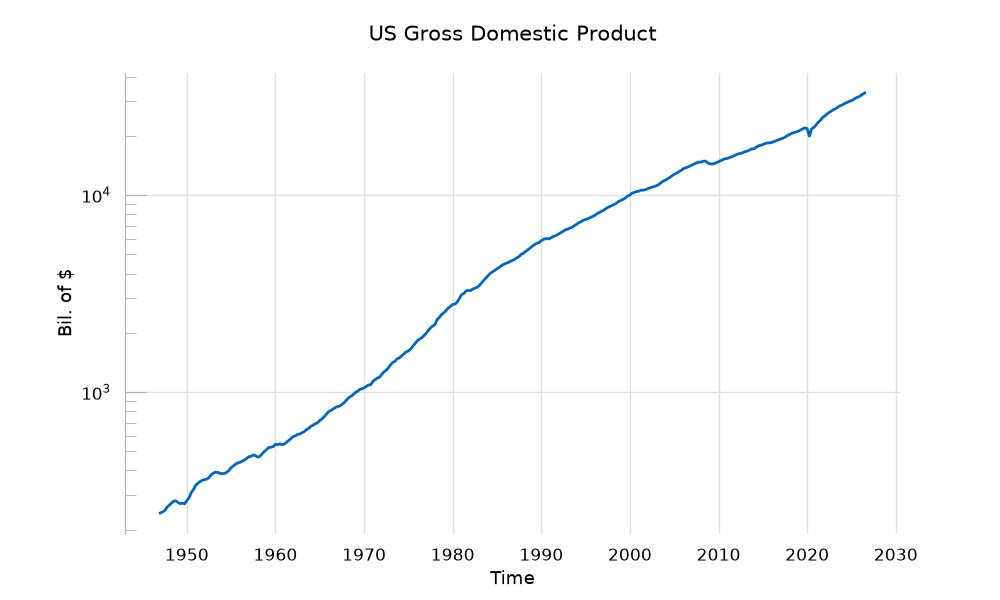

In [11]:
result = await call_tool("plot_series", {
    "series_ids": ["GDP"],
    "title": "US Gross Domestic Product",
})
show_result(result)

### `fetch_fred_series` — the explicit `cache_id` path

`plot_series` fetches for you, so this is only needed when the id is wanted
*before* a chart: to build a report, or to hold a series across several plots.

It returns the metadata and the id, and deliberately **not** the observations —
those stay in the cache so they cannot be paraphrased on the way out. Idempotent:
fetching the same series again returns the same `cache_id` and re-reads FRED only
once the cached copy is stale.

Note the renderer. `show_structured` is wrong here — it prints `status` and drops
`cache_id`, the one field this tool exists to return — so this uses
`print_json_vertical` instead.

In [12]:
from lib.utils import print_json_vertical

gdp_entry = (await call_tool("fetch_fred_series", {"series_id": "GDP"})).structured_content
unrate_entry = (await call_tool("fetch_fred_series", {"series_id": "UNRATE"})).structured_content

print_json_vertical(gdp_entry)

{
  "cache_id": "ad303470-59df-4d3a-9cfb-7bbd328151da",
  "detail": "Pass cache_id to plot_series. The observations are in the cache, not in this reply, and should not be reproduced from memory.",
  "frequency": "Q",
  "native_id": "GDP",
  "observation_count": 323,
  "observation_end": "2026-07-01",
  "observation_start": "1946-01-01",
  "source": "fred",
  "status": "ok",
  "title": "Gross Domestic Product",
  "units": "Bil. of $"
}


GDP and unemployment, from cache ids — twinx plot of 2 series from cache

| ID     | Units     | Axis  | Series |
|--------|-----------|-------|--------|
| GDP    | Bil. of $ | left  | Gross Domestic Product |
| UNRATE | %         | right | Unemployment Rate |

[image/png] 66,298 bytes (88,400 base64 chars)


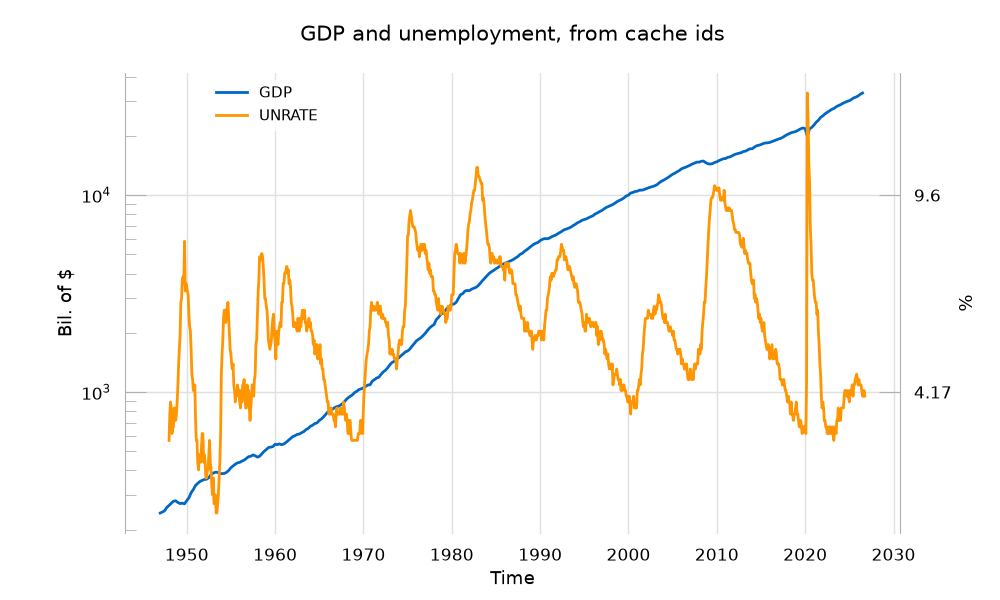

In [13]:
result = await call_tool("plot_series", {
    "cache_ids": [gdp_entry["cache_id"], unrate_entry["cache_id"]],
    "title": "GDP and unemployment, from cache ids",
})
show_result(result)

### Several series — the plot type is chosen, not asked for

There is no `plot_type` argument. `_select_plot_type`
(`time_series_report_plot_agent.py:123`) keys off the series count and the number
of **distinct unit strings**, with no LLM involved:

| series | distinct units | plot type | axes | example below |
|---|---|---|---|---|
| 1 | — | `single` | one | `GDP` |
| any | 1 | `comparison` | one, shared | `UNRATE + U6RATE` — both *%* |
| 2 | 2 | `twinx` | left and right | `GDP + UNRATE` |
| 3+ | 2 | `twinx_comparison` | majority unit left, the rest right | `GDP + GNP + UNRATE` |
| 3+ | 3+ | `stack` | one panel per series | `GDP + UNRATE + CPIAUCSL` |

Units are compared as literal strings, so `GDP` (*Bil. of $*) against `GDPC1`
(*Bil. of Chn. 2017 $*) counts as two units and earns a twin axis, while `GDP`
against `GNP` — both *Bil. of $* — shares one. The returned text names the type
it picked, which is the only way a client can tell.

The next cell draws one example of each, in table order.

single — 1 series — single plot of 1 series from cache

| ID  | Units     | Series |
|-----|-----------|--------|
| GDP | Bil. of $ | Gross Domestic Product |

[image/png] 30,100 bytes (40,136 base64 chars)


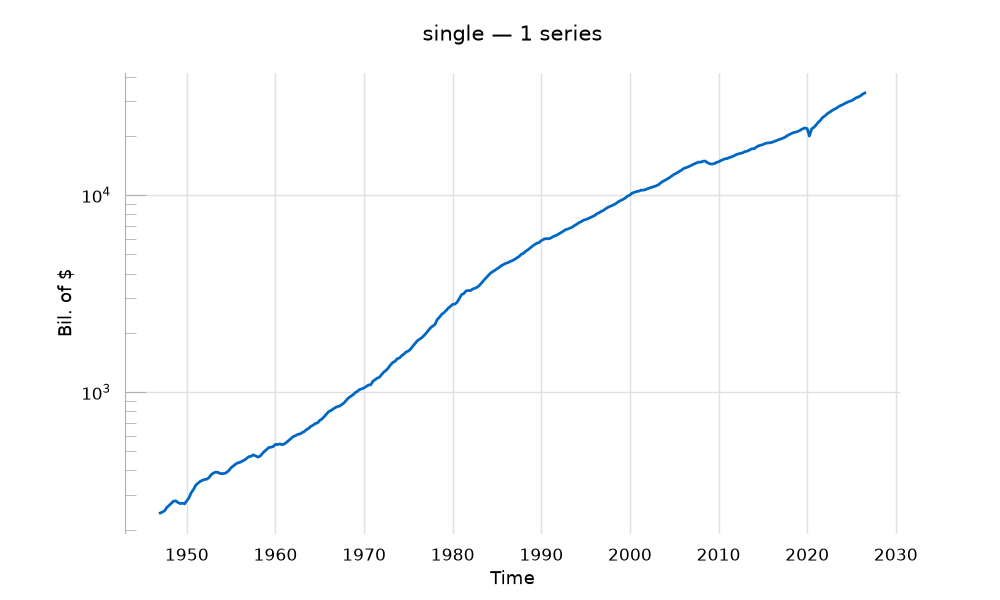

comparison — 2 series, both '%' — comparison plot of 2 series from cache

| ID     | Units | Series |
|--------|-------|--------|
| UNRATE | %     | Unemployment Rate |
| U6RATE | %     | Total Unemployed, Plus All Persons Marginally Attached to the Labor Force, Plus Total Employed Part Time for Economic Reasons, as a Percent of the Civilian Labor Force Plus All Persons Marginally Attached to the Labor Force (U-6) |

[image/png] 60,436 bytes (80,584 base64 chars)


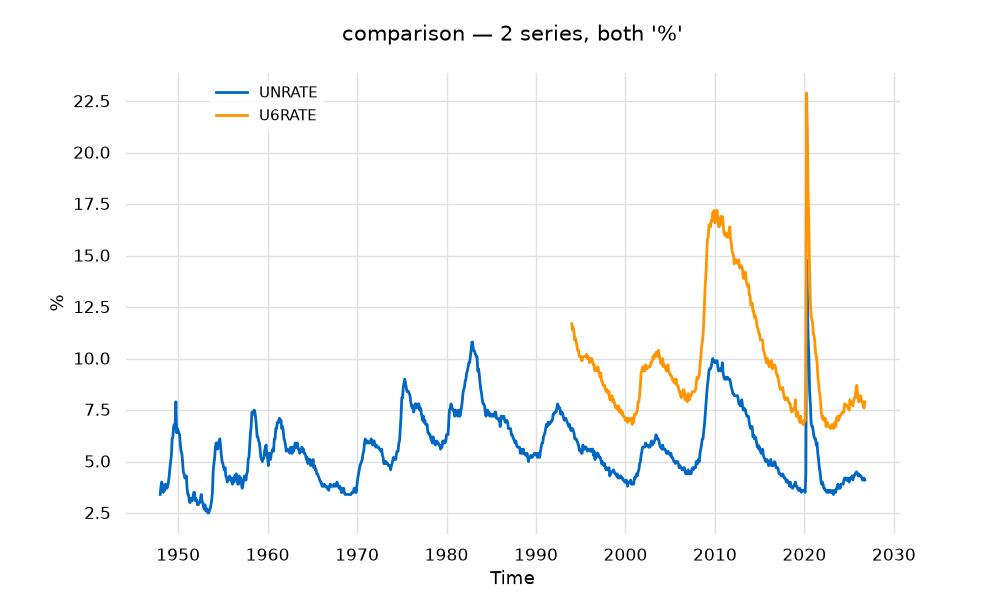

twinx — 2 series, units differ — twinx plot of 2 series from cache

| ID     | Units     | Axis  | Series |
|--------|-----------|-------|--------|
| GDP    | Bil. of $ | left  | Gross Domestic Product |
| UNRATE | %         | right | Unemployment Rate |

[image/png] 64,002 bytes (85,336 base64 chars)


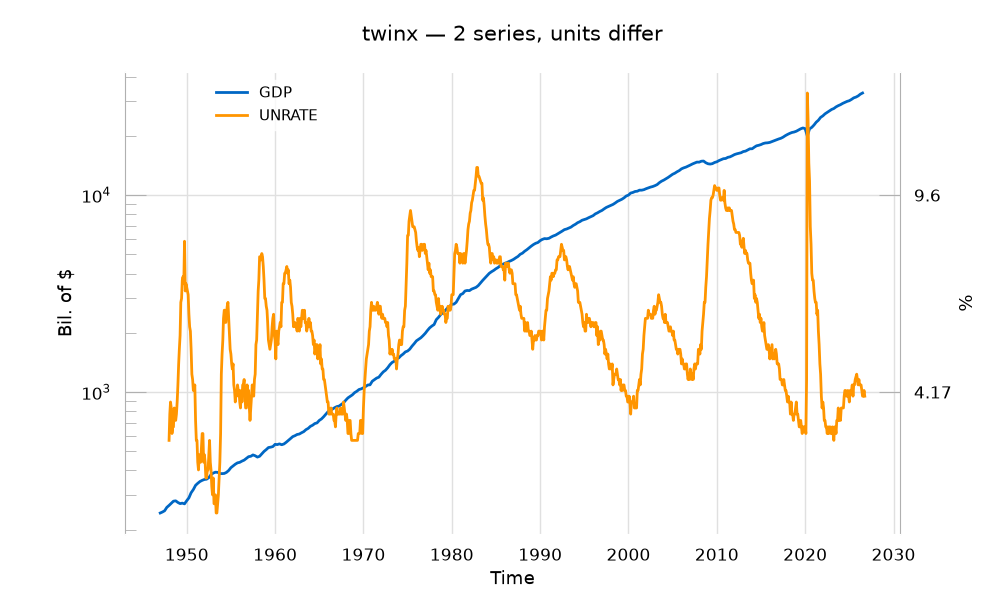

twinx_comparison — 3 series, 2 distinct units — twinx_comparison plot of 3 series from cache

| ID     | Units     | Axis  | Series |
|--------|-----------|-------|--------|
| GDP    | Bil. of $ | left  | Gross Domestic Product |
| GNP    | Bil. of $ | left  | Gross National Product |
| UNRATE | %         | right | Unemployment Rate |

[image/png] 72,595 bytes (96,796 base64 chars)


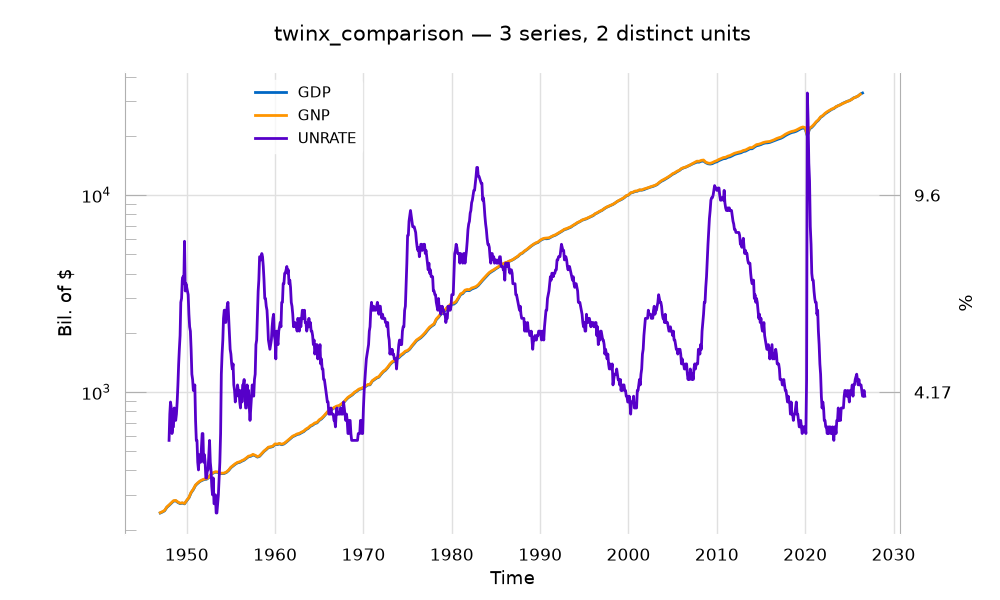

stack — 3 series, 3 distinct units — stack plot of 3 series from cache

| ID       | Units               | Series |
|----------|---------------------|--------|
| GDP      | Bil. of $           | Gross Domestic Product |
| UNRATE   | %                   | Unemployment Rate |
| CPIAUCSL | Index 1982-1984=100 | Consumer Price Index for All Urban Consumers: All Items in U.S. City Average |

[image/png] 65,758 bytes (87,680 base64 chars)


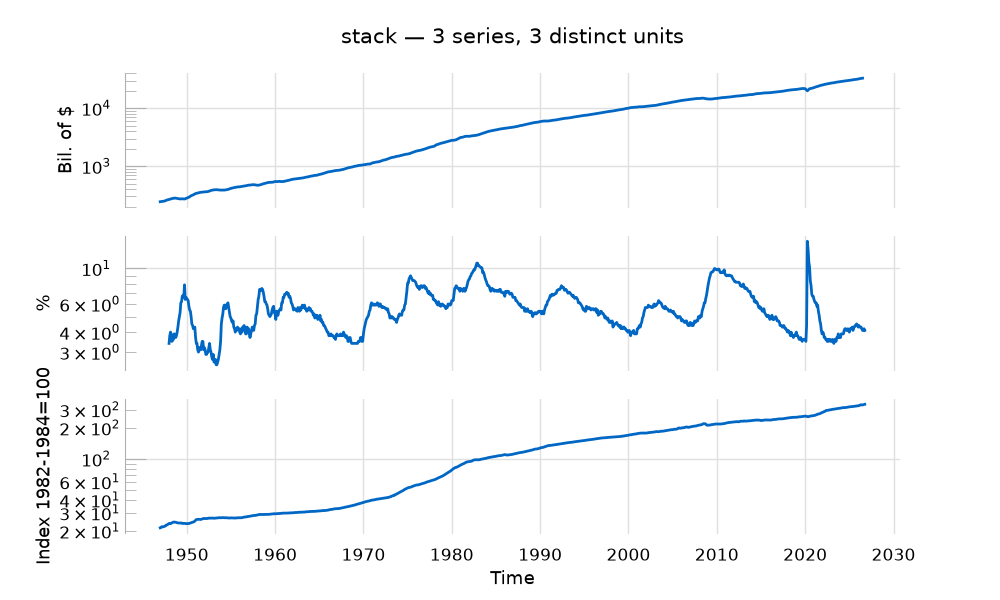

In [14]:
# One example of every branch, in table order. The summary line above each
# chart names the type the rule picked.
for ids, note in (
    (["GDP"],                        "single — 1 series"),
    (["UNRATE", "U6RATE"],           "comparison — 2 series, both '%'"),
    (["GDP", "UNRATE"],              "twinx — 2 series, units differ"),
    (["GDP", "GNP", "UNRATE"],       "twinx_comparison — 3 series, 2 distinct units"),
    (["GDP", "UNRATE", "CPIAUCSL"],  "stack — 3 series, 3 distinct units"),
):
    result = await call_tool("plot_series", {"series_ids": ids, "title": note})
    show_result(result)

### Series of different lengths were drawn misaligned

**Found and fixed 2026-11-24.** Kept here because the failure is worth
recognising: the charts it produced looked entirely right.

`render_series_plot` handed every branch **one** time vector —
`series[0]["time"]` — along with each series' own values, so the two were paired
by **array index**. navi then truncated to the shorter of the pair
(`npts = min(len(y), len(x))`, then `x = x[:npts]; y = y[:npts]` in
`plot_utils.py:39,66`), and `twinx` copied the first series' dates onto the
second (`numpy.tile(x, (2, 1))`, `line.py:400`).

Index pairing is correct only when every series has **identical** dates: same
frequency, same start, no gaps. Observed economic series satisfy none of that —
and the `None`/`"."` filter in `_load_series_by_cache_id` opens gaps even
between two series that otherwise agree. Frequency was never the real
discriminator: `UNRATE + U6RATE` are both monthly and were 46 years out, because
U6RATE starts in 1994.

The **values** were always right — they come from the cache, so the id-passing
rule held and nothing was fabricated. The **dates** were assigned by position.
That is the same class of failure `plot_series` exists to prevent, one layer
down: a chart that looks correct and is not.

Two fixes, because the second only surfaced once the first landed:

- **yada** — all four multi-series branches now pass one time array *per series*
  as a list, which navi already supported and `apps/backtrader/plots/dashboards.py`
  already used for buy/sell markers on their own dates.
- **navi** — `twinx_comparison` indexed the right-hand curves' x as `x[i]`
  instead of `x[len(left) + i]`, so they took the *left* curves' dates. Invisible
  while x was a tiled single vector, wrong the moment per-curve arrays arrive.

The cell below measures what it used to do, from the fetch metadata alone.

In [15]:
from datetime import date

npts = min(gdp_entry["observation_count"], unrate_entry["observation_count"])

# UNRATE is monthly and regular, so its npts-th date is exactly start + (npts-1) months.
start = date.fromisoformat(unrate_entry["observation_start"])
months = start.month - 1 + npts - 1
last_drawn = date(start.year + months // 12, months % 12 + 1, 1)

for s in (gdp_entry, unrate_entry):
    print(f"{s['native_id']:8} {s['frequency']}  n={s['observation_count']:4}  "
          f"{s['observation_start']} .. {s['observation_end']}")

print(f"\nnpts = min = {npts}\n")
print(f"x-axis drawn      : {gdp_entry['observation_start']} .. "
      f"{gdp_entry['observation_end']}  (GDP's dates)")
print(f"UNRATE drawn      : {unrate_entry['observation_start']} .. {last_drawn}  "
      f"(its first {npts} points)")
print(f"UNRATE discarded  : {unrate_entry['observation_count'] - npts} observations, "
      f"ending {unrate_entry['observation_end']}, never drawn")

GDP      Q  n= 323  1946-01-01 .. 2026-07-01
UNRATE   M  n= 946  1948-01-01 .. 2026-10-01

npts = min = 323

x-axis drawn      : 1946-01-01 .. 2026-07-01  (GDP's dates)
UNRATE drawn      : 1948-01-01 .. 1974-11-01  (its first 323 points)
UNRATE discarded  : 623 observations, ending 2026-10-01, never drawn


### Failures: readable text, `isError` still `False`

Three failures — an id that is not a FRED series, no arguments at all, and a
`cache_id` that is not a UUID. Each comes back as a single text block with
`is_error=False`, exactly as `plot`'s refusal above does.

**Nothing on this server sets `isError`**, so a client that routes on it detects
none of these. The message is the error channel.

In [16]:
for args in ({"series_ids": ["NOTAREALSERIES"]},
             {},
             {"cache_ids": ["not-a-uuid"]}):
    result = await call_tool("plot_series", args)
    print(f"{str(args)[:40]:42} is_error={result.is_error}")
    print(f"    {first_text(result)}\n")

{'series_ids': ['NOTAREALSERIES']}         is_error=False
    Could not fetch 'NOTAREALSERIES'. If that is not an exact FRED series id, find it with search_fred — the id is the short code like 'GDP' or 'UNRATE', not the series title. Nothing was plotted.

{}                                         is_error=False
    Give series_ids (FRED ids like 'GDP') or cache_ids from fetch_fred_series.

{'cache_ids': ['not-a-uuid']}              is_error=False
    Could not plot: Not cache IDs: not-a-uuid. A cache ID is a UUID returned by a fetch; a series ID like 'GDP' identifies a series, not a fetched copy of it.



## plot_report

Deterministic: no LLM, no agent. Resolves a report by UUID or by a
case-insensitive substring of its title, loads its series from the cache and
renders them through the same `render_series_plot` the section above exercises.

This is the **id-passing** path at its purest — the model carries a report id
and never holds the values, so the numbers on the chart are always the stored
ones.

Two things the schema does not say. Lookups are **scoped to the caller's
token**: `owner=current_user_id()`, never an argument, so one person's reports
are not addressable by another's substring. And each series is **refreshed past
its TTL** before rendering, falling back to the persisted snapshot when the
source cannot be reached — a saved report always plots, even offline.

In [17]:
tool_name = "plot_report"
await show_tool_schema(tool_name, raw=True)


{
  "_meta": {
    "io.modelcontextprotocol/ui": {
      "resourceUri": "ui://yada/plot",
      "visibility": [
        "model",
        "app"
      ]
    },
    "ui": {
      "resourceUri": "ui://yada/plot",
      "visibility": [
        "model",
        "app"
      ]
    },
    "ui/resourceUri": "ui://yada/plot",
    "ui/visibility": [
      "model",
      "app"
    ]
  },
  "description": "Render a stored time series report as a chart and return it as an image. Takes a report UUID, or a case-insensitive substring of the report title. The chart is drawn from the series cached under that report \u2014 it is never built from values supplied in the request, so the returned numbers are always the stored ones. Plot type and axis scale are chosen automatically from the series count and their units. Use this whenever the user asks to see, plot, chart or visualise a report they have already created.",
  "inputSchema": {
    "properties": {
      "report_id_or_title": {
        "title": "Repo

In [18]:
await show_tool_schema(tool_name)


plot_report
  Render a stored time series report as a chart and return it as an image. Takes a report UUID, or a case-insensitive substring of the report title. The chart is drawn from the series cached under that report — it is never built from values supplied in the request, so the returned numbers are always the stored ones. Plot type and axis scale are chosen automatically from the series count and their units. Use this whenever the user asks to see, plot, chart or visualise a report they have already created.

  report_id_or_title   string   required


{'properties': {'report_id_or_title': {'title': 'Report Id Or Title',
   'type': 'string'}},
 'required': ['report_id_or_title'],
 'type': 'object',
 'title': 'plot_reportArguments'}

### Making a report, with the tool that now does

This cell used to write a row through the store, because nothing on this server
could create one: `search_fred` found a series, `fetch_fred_series` cached it,
`plot_series` drew it — but `create_time_series_report` lived inside
`TimeSeriesReportAgent`, reachable only from yada's own chat app. `plot_report`
could therefore only ever draw reports made somewhere else.

`create_report` closes that gap, and it is the same writer the browser's create
form and `POST /api/reports` call. That matters more than the convenience: the
form used to submit by resuming the agent graph, which handed the cache_ids the
user had just picked to three successive router models as free text before
anything checked them, where a dropped or reordered id was silent.

Reports are **owner-scoped**, and the owner is never an argument. `create_report`
stamps `created_by` from the bearer token on the message, exactly as
`plot_report` resolves `owner=current_user_id()` to read it back — so a report
this cell creates is visible to the next cell and invisible to anyone else.

`date_from` is optional: omitted, it is derived from the earliest observation
among the chosen series, which is also what the browser's series picker does.

The pair is deliberate. GDP is quarterly from 1947, UNRATE monthly from 1948 —
the combination that was drawn 52 years out before the fix above, so it is the
one worth having a stored report of.

In [19]:
from lib.utils import print_json_vertical

REPORT_TITLE = "GDP and Unemployment"

# Idempotent, so the notebook can be re-run. The match is on the EXACT title, not
# on search_reports' count: the section below deliberately creates a report whose
# title contains this one, and a run interrupted before it cleans up would
# otherwise look like a miss and create a third.
found = (await call_tool("search_reports", {"query": REPORT_TITLE})).structured_content
exact = [r for r in found["reports"] if r["report_title"] == REPORT_TITLE]

if exact:
    report = exact[0]
    print(f"already present: {report['report_id']}")
else:
    report = (await call_tool("create_report", {
        "report_title": REPORT_TITLE,
        "report_description": (
            "US GDP against the unemployment rate — quarterly against monthly, "
            "the pair that was drawn 52 years out before the per-series dates fix."),
        "cache_ids": [gdp_entry["cache_id"], unrate_entry["cache_id"]],
        "date_from": "1947-01-01",
    })).structured_content
    print(f"created: {report['report_id']}")

report_id = report["report_id"]
print_json_vertical(report)

created: 4ba7b4eb-a0dc-4c77-ae63-8a89df2509a8
{
  "report_description": "US GDP against the unemployment rate \u2014 quarterly against monthly, the pair that was drawn 52 years out before the per-series dates fix.",
  "report_id": "4ba7b4eb-a0dc-4c77-ae63-8a89df2509a8",
  "report_title": "GDP and Unemployment",
  "series": [
    "GDP",
    "UNRATE"
  ],
  "series_count": 2,
  "status": "ok",
  "time_range_from": "1947-01-01",
  "time_range_to": null
}


### Three ways in, one report

A UUID, the exact title, and a case-insensitive substring of it all resolve to
the same row. The substring is the affordance that makes the tool usable from
chat — nobody types a UUID — and it is also the one that can be ambiguous, since
nothing makes titles unique.

Note what the chart is: GDP quarterly against UNRATE monthly, drawn through
`render_series_plot`, the same function the `plot_series` section above
exercises. `plot_report` adds the lookup and a per-series TTL refresh; the
drawing rules — plot type from count and units, one time array per series — are
shared. So the fix above covers this path too.

'4ba7b4eb-a0dc-4c77-ae63-8a89df2509a8'     -> GDP and Unemployment — twinx plot of 2 series
'GDP and Unemployment'                     -> GDP and Unemployment — twinx plot of 2 series
'unemployment'                             -> GDP and Unemployment — twinx plot of 2 series


GDP and Unemployment — twinx plot of 2 series (report_id 4ba7b4eb-a0dc-4c77-ae63-8a89df2509a8)

| ID     | Units     | Axis  | Series |
|--------|-----------|-------|--------|
| GDP    | Bil. of $ | left  | Gross Domestic Product |
| UNRATE | %         | right | Unemployment Rate |

[image/png] 64,322 bytes (85,764 base64 chars)


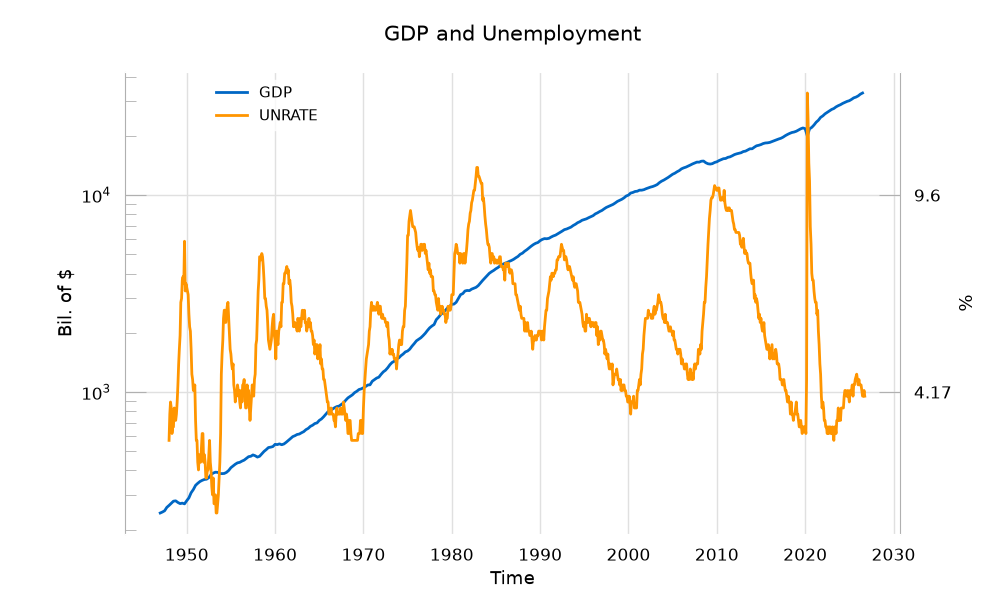

In [20]:
#  A UUID, the exact title, and a substring of it all resolve to the same report.
for lookup in (report_id, REPORT_TITLE, "unemployment"):
    result = await call_tool("plot_report", {"report_id_or_title": lookup})
    print(f"{lookup!r:42} -> {first_text(result).split(' (report_id')[0]}")

# Draw the last one.
show_result(result)

### When it finds nothing

A title that matches no report, and a well-formed UUID that is not a report id.
Both come back as text with `is_error=False`, the same convention as every other
failure on this server.

The malformed-id case matters more than it looks: `report_id_or_title` is one
string, so a value that parses as a UUID is looked up as an id and a value that
does not is matched as a title. A UUID that simply isn't there has to fall
through to the title path and miss, rather than raise.

In [21]:
for lookup in ("nothing matches this", "00000000-0000-0000-0000-000000000000"):
    result = await call_tool("plot_report", {"report_id_or_title": lookup})
    print(f"{lookup!r:42} is_error={result.is_error}")
    print(f"    {first_text(result)}\n")

'nothing matches this'                     is_error=False
    Could not plot report: No report found matching 'nothing matches this'.

'00000000-0000-0000-0000-000000000000'     is_error=False
    Could not plot report: No report found matching '00000000-0000-0000-0000-000000000000'.



## list_reports and search_reports

The two read verbs beside `create_report`. Both return metadata only — titles,
ids, series counts and date ranges — never observations, the same rule
`fetch_fred_series` follows.

`search_reports` is the one that matters for routing. Titles are **not unique**
and the match is a substring, so "GDP" legitimately means several reports. It
returns however many matched rather than picking one, and a miss is `count: 0`
with `status: "ok"` — not an error, because finding nothing is a real answer to
a search.

That shape is shared. `plot_report`, `POST /api/reports/{id}/plot` and the chat
tool all resolve a reference through the same function, so an ambiguous title
reads the same from every door: the candidates, never a guess. The cell below
creates a deliberate collision to show it.

In [22]:
def show_reports(label, payload):
    print(f"{label}  count={payload['count']}")
    for r in payload["reports"]:
        span = f"{r['time_range_from']} .. {r['time_range_to'] or 'latest'}"
        print(f"    {r['report_title']:34} {r['series_count']} series  "
              f"{span:26} {','.join(r['series'])}")
    print()

show_reports("list_reports", (await call_tool("list_reports", {})).structured_content)

for q in (REPORT_TITLE, "unemployment", "nothing matches this"):
    show_reports(f"search_reports {q!r}",
                 (await call_tool("search_reports", {"query": q})).structured_content)

# A deliberate collision: a second report whose title CONTAINS the first's, so a
# substring search for REPORT_TITLE now matches two. Removed again at the end of
# the cell, which is what keeps this notebook re-runnable.
twin = (await call_tool("create_report", {
    "report_title": f"{REPORT_TITLE} (monthly only)",
    "cache_ids": [unrate_entry["cache_id"]],
})).structured_content
print(f"created {twin['report_id']} to collide with {REPORT_TITLE!r}\n")

show_reports(f"search_reports {REPORT_TITLE!r}",
             (await call_tool("search_reports", {"query": REPORT_TITLE})).structured_content)

# Every door reports the ambiguity the same way, and none of them picks one.
result = await call_tool("plot_report", {"report_id_or_title": REPORT_TITLE})
print(f"plot_report  is_error={result.is_error}\n    {first_text(result)}\n")

# delete_report takes an id, never a title — a substring that matched two would
# make deletion a guess.
print((await call_tool("delete_report",
                       {"report_id": twin["report_id"]})).structured_content)
show_reports(f"search_reports {REPORT_TITLE!r} after the delete",
             (await call_tool("search_reports", {"query": REPORT_TITLE})).structured_content)

list_reports  count=2
    Crude Oil Prices                   0 series  1986-01-02 .. latest       
    GDP and Unemployment               0 series  1947-01-01 .. latest       

search_reports 'GDP and Unemployment'  count=1
    GDP and Unemployment               2 series  1947-01-01 .. latest       GDP,UNRATE

search_reports 'unemployment'  count=1
    GDP and Unemployment               2 series  1947-01-01 .. latest       GDP,UNRATE

search_reports 'nothing matches this'  count=0

created 29341acb-cefd-4df5-811b-d78f3318f60c to collide with 'GDP and Unemployment'

search_reports 'GDP and Unemployment'  count=2
    GDP and Unemployment               2 series  1947-01-01 .. latest       GDP,UNRATE
    GDP and Unemployment (monthly only) 1 series  1948-01-01 .. latest       UNRATE

plot_report  is_error=False
    Could not plot report: 2 reports match 'GDP and Unemployment' — plot one by its id: GDP and Unemployment (4ba7b4eb-a0dc-4c77-ae63-8a89df2509a8); GDP and Unemployment (monthly on